# House Prices — Advanced Regression Techniques

**ML Assignment 1** · [Kaggle competition](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

---
## 1. Setup

Running a reusable path and making sure that my path is always consistent to the original root folder. Claude helped me do this so it didn't crash after it did multiple times.

In [226]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
SUBMISSION_DIR = PROJECT_ROOT / "submissions"
FIGURE_DIR = PROJECT_ROOT / "report" / "figures"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

print("pandas", pd.__version__, "| numpy", np.__version__)
print("root  ", PROJECT_ROOT)

pandas 3.0.6 | numpy 2.4.6
root   /Users/santiagolandinez/Desktop/ML_Assignment_1


---
## 2. Loading the data

I am loading the data and separating the test IDs as they are not going to help the model learn, but keeping them for later as I have to submit them in kaggle.

In [227]:
train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

test_ids = test["Id"].copy()          # needed to build the submission
train = train.drop(columns="Id")
test = test.drop(columns="Id")

print(f"train : {train.shape[0]:>5} x {train.shape[1]:>3}")
print(f"test  : {test.shape[0]:>5} x {test.shape[1]:>3}")

train :  1460 x  80
test  :  1459 x  79


---
## 3. Exploratory Data Analysis


In [228]:
train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [229]:
# The only column train has and test lacks should be the target.
print("only in train :", sorted(set(train.columns) - set(test.columns)))
print("only in test  :", sorted(set(test.columns) - set(train.columns)))

only in train : ['SalePrice']
only in test  : []


In [230]:
features = train.drop(columns="SalePrice")

print(f"numeric     : {features.select_dtypes(include='number').shape[1]:>3}")
print(f"categorical : {features.select_dtypes(exclude='number').shape[1]:>3}")
print(f"total       : {features.shape[1]:>3}")

numeric     :  36
categorical :  43
total       :  79


In [231]:
train["SalePrice"].describe().apply(lambda v: f"{v:,.0f}").to_frame("SalePrice ($)")

,SalePrice ($)
count,"1,460"
mean,"180,921"
std,"79,443"
min,"34,900"
25%,"129,975"
50%,"163,000"
75%,"214,000"
max,"755,000"


In [287]:
train.shape


(1460, 80)

In [288]:
test.shape

(1459, 79)

---
## 4. Analyzing data type

### MSSubClass is in the wrong group

It is stored as an integer, so it is counted as numeric in the dataset. After looking at it I found that its values are dwelling-type codes (shown in the data_description):
`20` = 1-storey post-1946, `90` = duplex, `190` = 2-family conversion, etc. This is giving it inherent order which is wrong as a type of household is not necessarily better than the other, and if it is which can be the case because of price, the order given in the original dataset is wrong so I will have to re-encode it and treat it as nominal data which I think is more fitting.

In [232]:
for df in (train, test):
    df["MSSubClass"] = df["MSSubClass"].astype(str)

print("MSSubClass ->", train["MSSubClass"].dtype, "|", train["MSSubClass"].nunique(), "categories")

MSSubClass -> str | 15 categories


### Ordinal mappings


- **`Fence`** (`GdPrv, MnPrv, GdWo, MnWw`) should also be treated as nominal due to it being a mix of two factors
- **`Electrical`** I believe should also be nominal due to it having 'mix' as one of its options which if is given a number could damage the model.

Several columns use `NA` rather than *unknown* which is a big problem I will have to address by making them '0'. This could be an issue as it is inherently putting NA and unknown as the less than any other category, but it is the decision I am taking and I would rather these be treated as '0' than having to impute them with the mean or KNN which I find usually ends up inflating some values.

In [233]:
QUALITY_SCALE = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

ORDINAL_MAPPINGS = {
    "ExterQual":    QUALITY_SCALE,
    "ExterCond":    QUALITY_SCALE,
    "BsmtQual":     QUALITY_SCALE,
    "BsmtCond":     QUALITY_SCALE,
    "HeatingQC":    QUALITY_SCALE,
    "KitchenQual":  QUALITY_SCALE,
    "FireplaceQu":  QUALITY_SCALE,
    "GarageQual":   QUALITY_SCALE,
    "GarageCond":   QUALITY_SCALE,
    "PoolQC":       QUALITY_SCALE,
    "BsmtExposure": {"No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4,
                     "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "PavedDrive":   {"N": 1, "P": 2, "Y": 3},
    "Utilities":    {"ELO": 1, "NoSeWa": 2, "NoSewr": 3, "AllPub": 4},
    "CentralAir":   {"N": 0, "Y": 1},
}

# NA here means "the house doesn't have one", not "we don't know" -> fill with 0 later.
ABSENT_MEANS_NONE = {
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageQual", "GarageCond", "GarageFinish", "PoolQC",
}

print(len(ORDINAL_MAPPINGS), "ordinal columns |", len(ABSENT_MEANS_NONE), "where NA means absent")

20 ordinal columns | 10 where NA means absent


### Grouping the features




In [234]:
TARGET = "SalePrice"
FEATURE_COLS = [c for c in train.columns if c != TARGET]

ORDINAL_COLS = [c for c in FEATURE_COLS if c in ORDINAL_MAPPINGS]
NUMERIC_COLS = [c for c in FEATURE_COLS
                if c not in ORDINAL_MAPPINGS and pd.api.types.is_numeric_dtype(train[c])]
NOMINAL_COLS = [c for c in FEATURE_COLS
                if c not in ORDINAL_MAPPINGS and not pd.api.types.is_numeric_dtype(train[c])]

assert len(ORDINAL_COLS) + len(NUMERIC_COLS) + len(NOMINAL_COLS) == len(FEATURE_COLS)

print(f"numeric : {len(NUMERIC_COLS):>3}")
print(f"ordinal : {len(ORDINAL_COLS):>3}")
print(f"nominal : {len(NOMINAL_COLS):>3}")
print(f"total   : {len(FEATURE_COLS):>3}")

print("\nHighest-cardinality nominals:")
print(train[NOMINAL_COLS].nunique().sort_values(ascending=False).head(5).to_string())

numeric :  35
ordinal :  20
nominal :  24
total   :  79

Highest-cardinality nominals:
Neighborhood    25
Exterior2nd     16
MSSubClass      15
Exterior1st     15
SaleType         9


In [235]:
# 1459 of 1460 houses share one value — nothing for a model to split on.
print(train["Utilities"].value_counts().to_string())

Utilities
AllPub    1459
NoSeWa       1


---
## 5. The target variable

Analyzing the target variable

In [236]:
y_raw = train[TARGET]

print(f"min    {y_raw.min():>10,.0f}")
print(f"median {y_raw.median():>10,.0f}")
print(f"mean   {y_raw.mean():>10,.0f}")
print(f"max    {y_raw.max():>10,.0f}")
print(f"\nskew      {y_raw.skew():.3f}")
print(f"kurtosis  {y_raw.kurtosis():.3f}")

min        34,900
median    163,000
mean      180,921
max       755,000

skew      1.883
kurtosis  6.536


With the skewness being high I find that the best way to normalize this variable is with a simple log. This is what I understand the example notebook is doing too. 


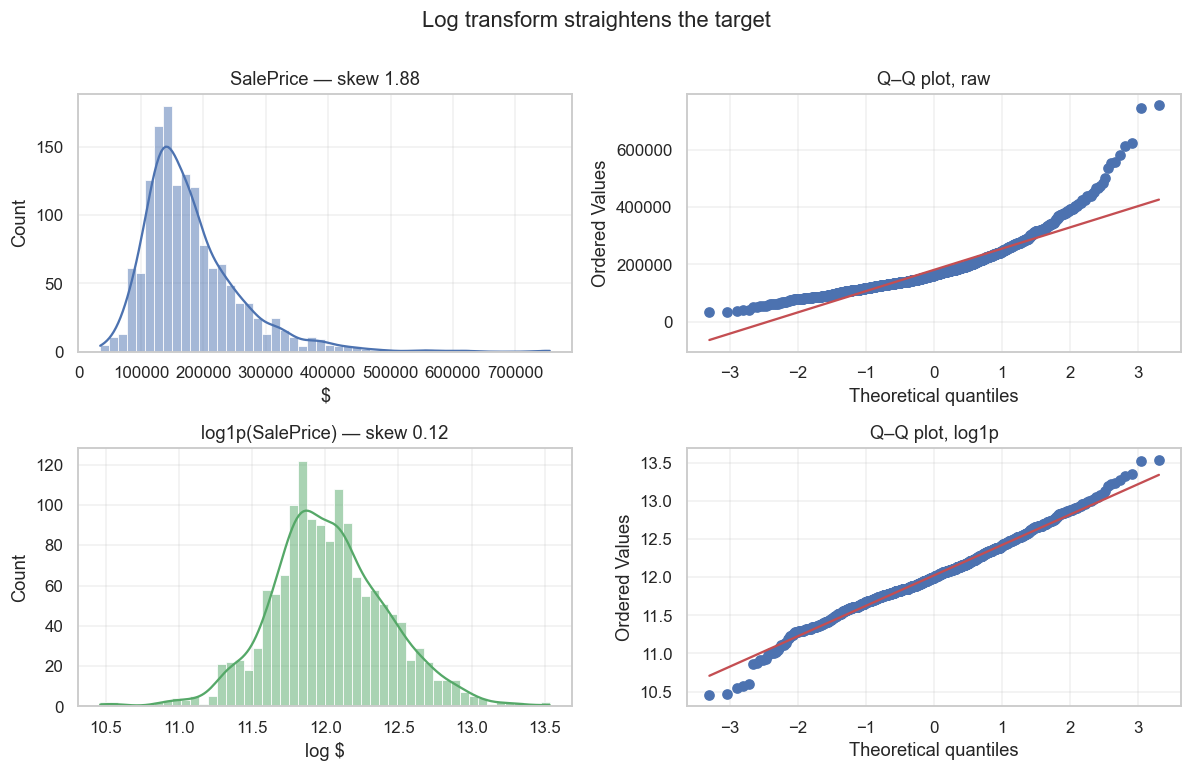

In [237]:
from scipy import stats

y_log = np.log1p(y_raw)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# Row 1: raw dollars
sns.histplot(y_raw, bins=50, kde=True, ax=axes[0, 0], color="#4c72b0", edgecolor="white", linewidth=0.5)
axes[0, 0].set_title(f"SalePrice — skew {y_raw.skew():.2f}")
axes[0, 0].set_xlabel("$")

stats.probplot(y_raw, plot=axes[0, 1])
axes[0, 1].set_title("Q–Q plot, raw")

# Row 2: after log1p
sns.histplot(y_log, bins=50, kde=True, ax=axes[1, 0], color="#55a868", edgecolor="white", linewidth=0.5)
axes[1, 0].set_title(f"log1p(SalePrice) — skew {y_log.skew():.2f}")
axes[1, 0].set_xlabel("log $")

stats.probplot(y_log, plot=axes[1, 1])
axes[1, 1].set_title("Q–Q plot, log1p")

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle("Log transform straightens the target", y=1.00)
fig.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / "target_distribution.png", bbox_inches="tight")
plt.show()

It is clear to me that after applying a log, the data is extremely more symmetric as seen in the plots above. I also believe this is crucial for the competition as I am trying to reduce the RMSE which is heavily affected by large numbers and with skewed data this will be a clear issue, therefore applying log will help extremely. From what we learned in past classes this is common practice and I hope it will reduce the loss when I actually train my models. 




In [238]:
y = np.log1p(train[TARGET])
X = train.drop(columns=TARGET)

print(f"X {X.shape}   y {y.shape}")
print(f"y range  {y.min():.2f} .. {y.max():.2f}   (expm1 -> {np.expm1(y.min()):,.0f} .. {np.expm1(y.max()):,.0f})")

X (1460, 79)   y (1460,)
y range  10.46 .. 13.53   (expm1 -> 34,900 .. 755,000)


---
## 6. Missing data


In [239]:
missing = pd.DataFrame({"train": X.isna().sum(), "test": test.isna().sum()})
missing = missing[(missing.train > 0) | (missing.test > 0)]
missing["train_%"] = (missing.train / len(X) * 100).round(1)
missing["test_%"] = (missing.test / len(test) * 100).round(1)
missing = missing.sort_values("train_%", ascending=False)

test_only = sorted(missing.index[(missing.train == 0) & (missing.test > 0)])

print(f"columns with gaps — train: {(missing.train > 0).sum()}   test: {(missing.test > 0).sum()}")
print(f"\nmissing in test but NOT in train ({len(test_only)}):")
print(" ", ", ".join(test_only))
missing.head(20)

columns with gaps — train: 19   test: 33

missing in test but NOT in train (15):
  BsmtFinSF1, BsmtFinSF2, BsmtFullBath, BsmtHalfBath, BsmtUnfSF, Exterior1st, Exterior2nd, Functional, GarageArea, GarageCars, KitchenQual, MSZoning, SaleType, TotalBsmtSF, Utilities


,train,test,train_%,test_%
PoolQC,1453,1456,99.5,99.8
MiscFeature,1406,1408,96.3,96.5
Alley,1369,1352,93.8,92.7
Fence,1179,1169,80.8,80.1
MasVnrType,872,894,59.7,61.3
FireplaceQu,690,730,47.3,50.0
LotFrontage,259,227,17.7,15.6
GarageType,81,76,5.5,5.2
GarageYrBlt,81,78,5.5,5.3
GarageFinish,81,78,5.5,5.3


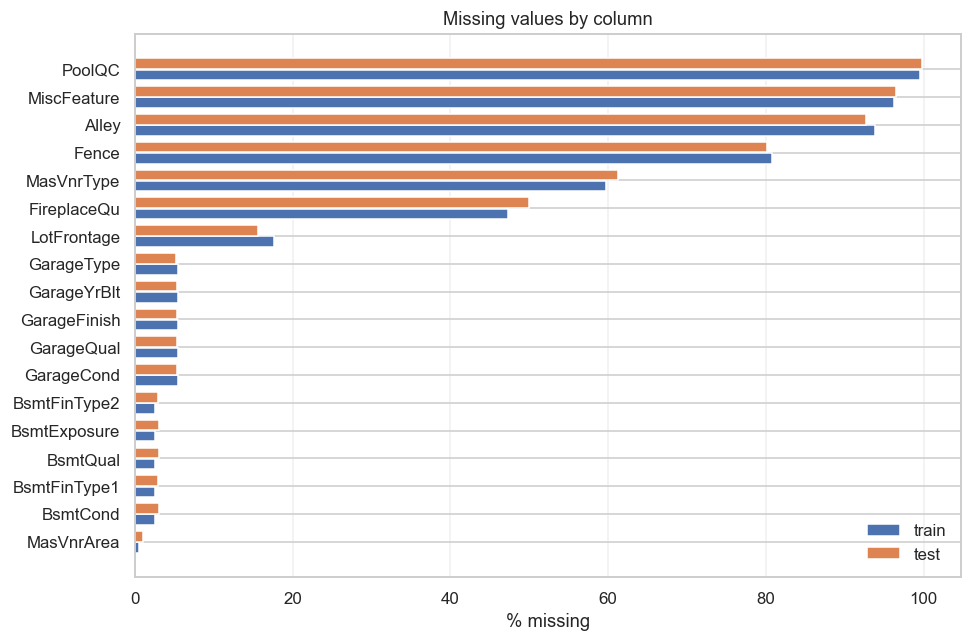

In [240]:
top = missing.head(18).sort_values("train_%")

fig, ax = plt.subplots(figsize=(9, 6))
ypos = np.arange(len(top))
ax.barh(ypos - 0.2, top["train_%"], height=0.38, label="train", color="#4c72b0")
ax.barh(ypos + 0.2, top["test_%"], height=0.38, label="test", color="#dd8452")
ax.set_yticks(ypos, top.index)
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "missing_values.png", bbox_inches="tight")
plt.show()

### Types of missing values identified 

**Structural** — `PoolQC` is blank for 99.5% of houses which initially scared me, but after analyzing the variable, I found that it is because most houses simply do not have a pool so they are marked as missing. This makes it really easy as I can simply replace the missing values with 'none' as they are categorical.
**Unknown** — `LotFrontage` In this case it seems that the missing values are actually missing meaning I will have to impute them with another algorithm that isn't simply adding zeros. 

I am only mentioning 1 of each as now that I got to see there are too many, but I will impute these separately as structural and unknown. Some of the structural I will leave and 'none' and some as '0' depending on the type of variable either being numeric or categorical. 


In [241]:
STRUCTURAL_NONE = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]

STRUCTURAL_ZERO = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea",
]

# Genuinely unrecorded — these need an estimate.
UNKNOWN = sorted(set(missing.index) - set(STRUCTURAL_NONE) - set(STRUCTURAL_ZERO))

print(f"structural (categorical) : {len(STRUCTURAL_NONE)}")
print(f"structural (numeric)     : {len(STRUCTURAL_ZERO)}")
print(f"genuinely unknown        : {len(UNKNOWN)}")
print(" ", ", ".join(UNKNOWN))

structural (categorical) : 15
structural (numeric)     : 9
genuinely unknown        : 10
  Electrical, Exterior1st, Exterior2nd, Functional, GarageYrBlt, KitchenQual, LotFrontage, MSZoning, SaleType, Utilities


### Where leakage gets in

Filling `PoolQC` with 'none' will have no issue with leakage and so do the other variables I worked with. 

Filling `LotFrontage` with a median is different: that median is taken from the data so I will be careful to only take it from the train data and not the test and keep them separate or else the model will be able to learn from the test data without me noticing and will end up overfitting. I will now build a pipeline to stop this from happening.

---
## 7. The preprocessing pipeline

This part I used claude most to help as I didn't really know how to avoid leakage in data with code, I know mostly the theory. 

I will be one-hot encoding the variables which I consider nominal and am taking the risk that I will create a lot more features as I believe there is enough data in the dataset to compensate for the large amount of features. I am trying to prevent the data from learning anything incorrectly by label-encoding these and giving them numerical values that could cause the model to learn non-existent patterns. 

In [242]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NOMINAL_STRUCTURAL = [c for c in STRUCTURAL_NONE if c not in ORDINAL_MAPPINGS]


class DomainCleaner(BaseEstimator, TransformerMixin):
    """Deterministic fixes taken from the data dictionary. Learns nothing, so it cannot leak."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col, mapping in ORDINAL_MAPPINGS.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
                if col in ABSENT_MEANS_NONE:
                    X[col] = X[col].fillna(0)

        for col in NOMINAL_STRUCTURAL:
            if col in X.columns:
                X[col] = X[col].fillna("None")

        for col in STRUCTURAL_ZERO:
            if col in X.columns:
                X[col] = X[col].fillna(0)

        # A garage is normally built with the house.
        if "GarageYrBlt" in X.columns:
            X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])

        return X

After this, there should only be a couple values as unknown as they are actually unknown as I mentioned before. 

In [243]:
cleaned = DomainCleaner().fit_transform(X)

remaining = cleaned.isna().sum()
print(remaining[remaining > 0].to_string())

LotFrontage    259
Electrical       1


### Column groups after cleaning

I can now join everything as I already encoded the categorical variables. 

In [244]:
PIPE_NUMERIC = [c for c in cleaned.columns if pd.api.types.is_numeric_dtype(cleaned[c])]
PIPE_NOMINAL = [c for c in cleaned.columns if not pd.api.types.is_numeric_dtype(cleaned[c])]

print(f"numeric (incl. mapped ordinals) : {len(PIPE_NUMERIC)}")
print(f"nominal (to one-hot)            : {len(PIPE_NOMINAL)}")

numeric (incl. mapped ordinals) : 55
nominal (to one-hot)            : 24


In [245]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), PIPE_NUMERIC),
    ("nom", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), PIPE_NOMINAL),
])

preprocess = Pipeline([("clean", DomainCleaner()), ("prep", preprocessor)])

X_check = preprocess.fit_transform(X)
test_check = preprocess.transform(test)

print(f"train {X_check.shape}   test {test_check.shape}")
print(f"79 raw features -> {X_check.shape[1]} model features")
assert X_check.shape[1] == test_check.shape[1], "train/test width mismatch"
assert not np.isnan(X_check).any() and not np.isnan(test_check).any()
print("no NaN remaining, widths match")

train (1460, 242)   test (1459, 242)
79 raw features -> 242 model features
no NaN remaining, widths match


---
## 8. Cross-validation and the neural network

`shuffle=True` is used because as we learned in class we want to make sure that the model will not learn linear patterns created by inherent order. 

In [246]:
import torch
import torch.nn as nn
from sklearn.base import RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict

torch.set_num_threads(4)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def build_pipeline(model, scale=True):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    prep = ColumnTransformer([
        ("num", Pipeline(numeric_steps), PIPE_NUMERIC),
        ("nom", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), PIPE_NOMINAL),
    ])
    return Pipeline([("clean", DomainCleaner()), ("prep", prep), ("model", model)])

### Baseline: predict the mean

I am creating this model to then compare. If the models I create are better than this baseline I will consider them useful.

In [247]:
dummy_pipe = build_pipeline(DummyRegressor(strategy="mean"))

dummy_scores = -cross_val_score(dummy_pipe, X, y, cv=cv,
                                scoring="neg_root_mean_squared_error")

print("Dummy (mean)")
print("  folds :", np.round(dummy_scores, 4))
print(f"  mean  : {dummy_scores.mean():.4f}")
print(f"  std   : {dummy_scores.std():.4f}")

Dummy (mean)
  folds : [0.4332 0.3958 0.3754 0.421  0.3685]
  mean  : 0.3988
  std   : 0.0251


### The network

I am choosing to use Batches, ReLU activation and dropout as from what we learned in class they will prevent overfitting and ReLU will help with non-linearity in a larger range which I hope will help the model learn faster. 

In [248]:
class TabularMLP(nn.Module):
    """Fully-connected network for tabular regression."""

    def __init__(self, n_features, hidden=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, previous = [], n_features
        for width in hidden:
            layers += [
                nn.Linear(previous, width),
                nn.BatchNorm1d(width),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [249]:
class TorchMLPRegressor(BaseEstimator, RegressorMixin):

    def __init__(self, hidden=(256, 128, 64), dropout=0.3, lr=1e-3, weight_decay=1e-4,
                 batch_size=64, max_epochs=300, patience=25, val_fraction=0.15,
                 random_state=42):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_fraction = val_fraction
        self.random_state = random_state

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        # Standardise the target. Computed from training rows only.
        self.y_mean_, self.y_std_ = y.mean(), y.std()
        y_scaled = (y - self.y_mean_) / self.y_std_

        # Inner split for early stopping, carved out of the training fold.
        rng = np.random.RandomState(self.random_state)
        order = rng.permutation(len(X))
        n_val = max(1, int(len(X) * self.val_fraction))
        val_idx, train_idx = order[:n_val], order[n_val:]

        X_tr = torch.tensor(X[train_idx]); y_tr = torch.tensor(y_scaled[train_idx])
        X_va = torch.tensor(X[val_idx]);   y_va = torch.tensor(y_scaled[val_idx])

        self.model_ = TabularMLP(X.shape[1], self.hidden, self.dropout)
        optimiser = torch.optim.AdamW(self.model_.parameters(), lr=self.lr,
                                      weight_decay=self.weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimiser, factor=0.5, patience=8)
        criterion = nn.MSELoss()

        best_loss, best_state, epochs_without_gain = float("inf"), None, 0

        for epoch in range(self.max_epochs):
            self.model_.train()
            shuffled = torch.randperm(len(X_tr))
            for start in range(0, len(X_tr), self.batch_size):
                batch = shuffled[start:start + self.batch_size]
                if len(batch) < 2:            # BatchNorm needs at least 2 rows
                    continue
                optimiser.zero_grad()
                loss = criterion(self.model_(X_tr[batch]), y_tr[batch])
                loss.backward()
                optimiser.step()

            self.model_.eval()
            with torch.no_grad():
                val_loss = criterion(self.model_(X_va), y_va).item()
            scheduler.step(val_loss)

            if val_loss < best_loss - 1e-5:
                best_loss, epochs_without_gain = val_loss, 0
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                epochs_without_gain += 1
                if epochs_without_gain >= self.patience:
                    break

        self.best_epoch_ = epoch
        if best_state is not None:
            self.model_.load_state_dict(best_state)      # keep the best, not the last
        return self

    def predict(self, X):
        X = torch.tensor(np.asarray(X, dtype=np.float32))
        self.model_.eval()
        with torch.no_grad():
            scaled = self.model_(X).numpy()
        return scaled * self.y_std_ + self.y_mean_       # back to the log-price scale

In [250]:
mlp_pipe = build_pipeline(TorchMLPRegressor(random_state=RANDOM_STATE), scale=True)

mlp_scores = -cross_val_score(mlp_pipe, X, y, cv=cv,
                              scoring="neg_root_mean_squared_error")

print("Neural network")
print("  folds :", np.round(mlp_scores, 4))
print(f"  mean  : {mlp_scores.mean():.4f}")
print(f"  std   : {mlp_scores.std():.4f}")

Neural network
  folds : [0.1363 0.1422 0.2357 0.1362 0.1173]
  mean  : 0.1535
  std   : 0.0419


Using 5 folds as seen here and have a low std which seems good for moving on.

In [251]:
baseline = pd.DataFrame(
    {"Dummy (mean)": dummy_scores, "Neural network": mlp_scores},
    index=[f"fold {i + 1}" for i in range(5)],
).T
baseline["mean"] = baseline.mean(axis=1)
baseline["std"] = baseline.iloc[:, :5].std(axis=1)

improvement = 1 - baseline.loc["Neural network", "mean"] / baseline.loc["Dummy (mean)", "mean"]
print(f"The network reduces RMSE {improvement:.1%} below the mean-prediction baseline\n")
baseline.round(4)

The network reduces RMSE 61.5% below the mean-prediction baseline



,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
Dummy (mean),0.4332,0.3958,0.3754,0.4210,0.3685,0.3988,0.0281
Neural network,0.1363,0.1422,0.2357,0.1362,0.1173,0.1535,0.0469


Fold 3 is far worse than the other four which I want to analyze moving forward. The neural network is still proving to be extremely better than the baseline, so I can already say that my model is working.

In [252]:
mlp_oof = cross_val_predict(mlp_pipe, X, y, cv=cv)
mlp_error = pd.Series(np.abs(mlp_oof - y))

worst = mlp_error.nlargest(6).index
X.loc[worst, ["GrLivArea", "OverallQual", "YearBuilt", "SaleCondition", "Neighborhood"]].assign(
    actual=np.expm1(y[worst]).round(0),
    predicted=np.expm1(mlp_oof[worst]).round(0),
    log_error=mlp_error[worst].round(3),
)

,GrLivArea,OverallQual,YearBuilt,SaleCondition,Neighborhood,actual,predicted,log_error
1298,5642,10,2008,Partial,Edwards,160000.0,3194715.0,2.994
523,4676,10,2007,Partial,Edwards,184750.0,1102802.0,1.787
1182,4476,10,1996,Abnorml,NoRidge,745000.0,244182.0,1.115
30,1317,4,1920,Normal,IDOTRR,40000.0,95171.0,0.867
968,968,3,1910,Abnorml,OldTown,37900.0,84088.0,0.797
916,480,2,1949,Abnorml,IDOTRR,35311.0,78102.0,0.794


---
## 9. Outliers

I will test these to check if my data could have been affected by outliers. I will consider than any data point with GRLivArea greater than 4000 will be an outlier. 

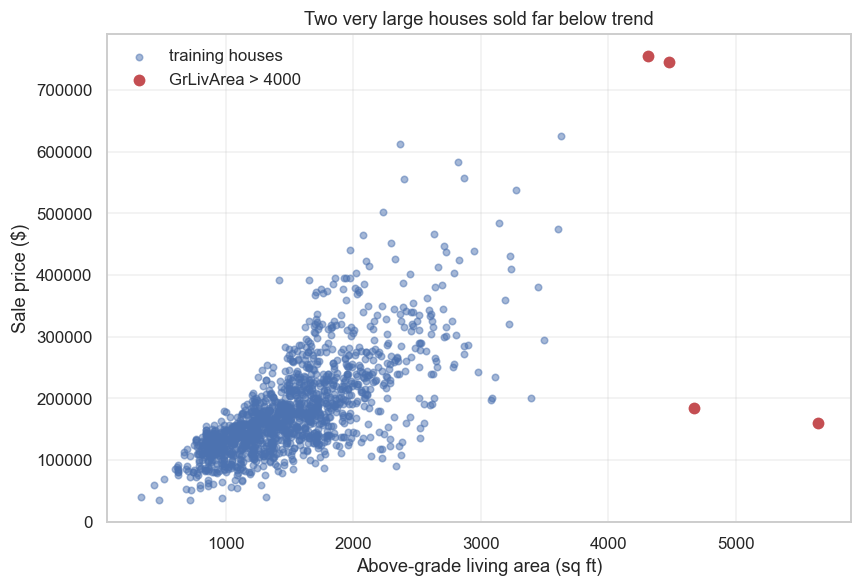

,GrLivArea,OverallQual,SaleCondition,price
523,4676,10,Partial,184750.0
691,4316,10,Normal,755000.0
1182,4476,10,Abnorml,745000.0
1298,5642,10,Partial,160000.0


In [253]:
is_large = X["GrLivArea"] >= 4000

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(X.loc[~is_large, "GrLivArea"], np.expm1(y[~is_large]),
           s=18, alpha=0.5, color="#4c72b0", label="training houses")
ax.scatter(X.loc[is_large, "GrLivArea"], np.expm1(y[is_large]),
           s=80, color="#c44e52", edgecolor="white", linewidth=1.2, zorder=3,
           label="GrLivArea > 4000")
ax.set_xlabel("Above-grade living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Two very large houses sold far below trend")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "outliers_grlivarea.png", bbox_inches="tight")
plt.show()

X.loc[is_large, ["GrLivArea", "OverallQual", "SaleCondition"]].assign(
    price=np.expm1(y[is_large]).round(0))

It appears that there are 4 outliers with extremely big houses. What is weird is that 2 are sold for what seems like a reasonable price, while the other 2 are sold for a very small amount of money. Due to this I am deciding to remove them from the training only to avoid leakage. 


Create the mask here so I can remove the rows with outliers.

In [254]:
TRIM_MASK = (X["GrLivArea"] < 4000).values
print(f"{(~TRIM_MASK).sum()} rows removed from training, {TRIM_MASK.sum()} remain")

4 rows removed from training, 1456 remain


In [255]:
# Network trained without the outliers, validated on untouched folds.
mlp_trim_scores = []

for train_idx, val_idx in cv.split(X):
    train_idx = train_idx[TRIM_MASK[train_idx]]          # trim training rows only
    pipe = build_pipeline(TorchMLPRegressor(random_state=RANDOM_STATE), scale=True)
    pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
    preds = pipe.predict(X.iloc[val_idx])
    mlp_trim_scores.append(np.sqrt(np.mean((preds - y.iloc[val_idx]) ** 2)))

mlp_trim_scores = np.array(mlp_trim_scores)

print("Neural network, outliers removed from training")
print("  folds :", np.round(mlp_trim_scores, 4))
print(f"  mean  : {mlp_trim_scores.mean():.4f}  (was {mlp_scores.mean():.4f})")

Neural network, outliers removed from training
  folds : [0.1336 0.1215 0.1999 0.1201 0.1082]
  mean  : 0.1367  (was 0.1535)


In [256]:
trim_effect = pd.DataFrame({
    "all rows": [mlp_scores.mean()],
    "trimmed":  [mlp_trim_scores.mean()],
}, index=["Neural network"])
trim_effect["change"] = trim_effect["trimmed"] - trim_effect["all rows"]
trim_effect.round(4)

,all rows,trimmed,change
Neural network,0.1535,0.1367,-0.0169


After trimming I can see that the model did improve so I will move on.

---
## 10. Feature engineering

### Skewed inputs

After looking at the dataset I found that there are multiple variables that are skewed just like the target which I already transformed. I am going to perform some transformations to normalize the data. I am deciding to transform any variable with a skewness greater than 0.75 which I researched and it seems that is considered high.

In [257]:
skewness = cleaned[PIPE_NUMERIC].skew().abs().sort_values(ascending=False)

print(f"{(skewness > 0.75).sum()} of {len(PIPE_NUMERIC)} numeric features have |skew| > 0.75\n")
skewness.head(10).round(2).to_frame("abs skew")

35 of 55 numeric features have |skew| > 0.75



,abs skew
Utilities,38.21
MiscVal,24.48
PoolQC,15.96
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01
Functional,4.91
LandSlope,4.81
KitchenAbvGr,4.49


I am deciding to log all of these numeric columns to make the distribution symmetric.

In [258]:
class SkewFixer(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        numeric = X.select_dtypes(include="number")
        self.cols_ = numeric.columns[numeric.skew().abs() > self.threshold].tolist()
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.cols_:
            if col in X.columns:
                X[col] = np.log1p(X[col].clip(lower=0))     # clip: log1p needs x > -1
        return X

### Derived features



I am deciding to join variables which are similar into one so the model can learn better from a single variable. For example I am joining all the variables that have anything to do with having a bathroom in the house and making it one by summing and aggregating the values.

In [259]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Combinations of existing columns. Row-wise arithmetic only, so nothing is learned."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
        X["TotalBath"] = (X["FullBath"] + 0.5 * X["HalfBath"]
                          + X["BsmtFullBath"] + 0.5 * X["BsmtHalfBath"])
        X["TotalPorchSF"] = (X["OpenPorchSF"] + X["EnclosedPorch"] + X["3SsnPorch"]
                             + X["ScreenPorch"] + X["WoodDeckSF"])

        X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
        X["RemodAge"] = X["YrSold"] - X["YearRemodAdd"]
        X["IsRemodeled"] = (X["YearRemodAdd"] != X["YearBuilt"]).astype(int)
        X["OverallGrade"] = X["OverallQual"] * X["OverallCond"]

        X["HasBsmt"] = (X["TotalBsmtSF"] > 0).astype(int)
        X["Has2ndFlr"] = (X["2ndFlrSF"] > 0).astype(int)
        X["HasGarage"] = (X["GarageArea"] > 0).astype(int)
        X["HasFireplace"] = (X["Fireplaces"] > 0).astype(int)
        X["HasPool"] = (X["PoolArea"] > 0).astype(int)

        return X

I am now recomputing the numeric column list.

In [260]:
# The derived features add columns, so the numeric list has to be recomputed.
engineered = FeatureEngineer().fit_transform(cleaned)
FE_NUMERIC = [c for c in engineered.columns if pd.api.types.is_numeric_dtype(engineered[c])]

print(f"{len(PIPE_NUMERIC)} numeric features -> {len(FE_NUMERIC)} after engineering")


def build_pipeline_fe(model, scale=True, use_features=True, use_skew=True):
    """Same as build_pipeline, with the two optional feature steps."""
    numeric_cols = FE_NUMERIC if use_features else PIPE_NUMERIC
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    prep = ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric_cols),
        ("nom", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), PIPE_NOMINAL),
    ])

    steps = [("clean", DomainCleaner())]
    if use_features:
        steps.append(("features", FeatureEngineer()))
    if use_skew:
        steps.append(("skew", SkewFixer()))
    steps += [("prep", prep), ("model", model)]
    return Pipeline(steps)

55 numeric features -> 67 after engineering


### Which of them actually helps

Same protocol as section 9: outliers trimmed from training folds only, validation folds untouched.

In [261]:
variants = {
    "trimmed only":    dict(use_features=False, use_skew=False),
    "+ skew fix":      dict(use_features=False, use_skew=True),
    "+ derived feats": dict(use_features=True,  use_skew=False),
    "+ both":          dict(use_features=True,  use_skew=True),
}

fe_results = {}
for label, options in variants.items():
    fold_rmse = []
    for train_idx, val_idx in cv.split(X):
        train_idx = train_idx[TRIM_MASK[train_idx]]
        pipe = build_pipeline_fe(TorchMLPRegressor(random_state=RANDOM_STATE), **options)
        pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
        preds = pipe.predict(X.iloc[val_idx])
        fold_rmse.append(np.sqrt(np.mean((preds - y.iloc[val_idx]) ** 2)))
    fe_results[label] = np.array(fold_rmse)
    print(f"{label:<18} {fe_results[label].mean():.4f} +/- {fe_results[label].std():.4f}")

trimmed only       0.1367 +/- 0.0326
+ skew fix         0.1334 +/- 0.0244
+ derived feats    0.1368 +/- 0.0378
+ both             0.1323 +/- 0.0277


In [262]:
fe_table = pd.DataFrame({k: {"CV RMSE": v.mean(), "std": v.std()} for k, v in fe_results.items()}).T
fe_table["vs trimmed only"] = fe_table["CV RMSE"] - fe_table.loc["trimmed only", "CV RMSE"]
fe_table.round(4)

,CV RMSE,std,vs trimmed only
trimmed only,0.1367,0.0326,0.0000
+ skew fix,0.1334,0.0244,-0.0032
+ derived feats,0.1368,0.0378,0.0002
+ both,0.1323,0.0277,-0.0043


The skew correction helps on average and in individual folds meaning the model is consistently getting better due to these transformations. 

I can now see that the derived features that I created do not actually change much in the model but I am deciding to keep them anyway as it was a valid attempt. 

---
## 11. Hyperparameter tuning

A random search over 24 configurations. I am deciding to do a random search rather than a grid search as it will take too much computational power and I do not believe it is worth it as there are some hyperparameters that are not equally important to others and doing a grid search will still exhaust this. 

In [263]:
def cv_score(seed=RANDOM_STATE, **params):
    """5-fold CV for one hyperparameter configuration."""
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    fold_rmse = []
    for train_idx, val_idx in folds.split(X):
        train_idx = train_idx[TRIM_MASK[train_idx]]
        pipe = build_pipeline_fe(TorchMLPRegressor(random_state=RANDOM_STATE, **params))
        pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
        preds = pipe.predict(X.iloc[val_idx])
        fold_rmse.append(np.sqrt(np.mean((preds - y.iloc[val_idx]) ** 2)))
    return np.array(fold_rmse)


SEARCH_SPACE = {
    "hidden":       [(256, 128, 64), (512, 256, 128), (256, 128),
                     (128, 64), (512, 256), (384, 192, 96)],
    "dropout":      [0.2, 0.3, 0.4, 0.5],
    "lr":           [5e-4, 1e-3, 2e-3],
    "weight_decay": [1e-5, 1e-4, 1e-3, 1e-2],
    "batch_size":   [32, 64, 128],
}

In [264]:
search_rng = np.random.RandomState(0)
trials, seen = [], set()

while len(trials) < 24:
    config = {k: v[search_rng.randint(len(v))] for k, v in SEARCH_SPACE.items()}
    key = str(sorted((k, str(v)) for k, v in config.items()))
    if key in seen:
        continue
    seen.add(key)

    scores = cv_score(**config)
    trials.append({**config, "cv_rmse": scores.mean(), "std": scores.std()})
    print(f"{len(trials):>2}/24  {scores.mean():.4f}  {str(config['hidden']):<16}"
          f" d{config['dropout']} lr{config['lr']:g}"
          f" wd{config['weight_decay']:g} bs{config['batch_size']}")

 1/24  0.1336  (512, 256)       d0.5 lr0.001 wd1e-05 bs64
 2/24  0.1334  (128, 64)        d0.3 lr0.002 wd1e-05 bs128
 3/24  0.1407  (256, 128, 64)   d0.2 lr0.0005 wd0.001 bs64
 4/24  0.1323  (256, 128, 64)   d0.3 lr0.001 wd0.0001 bs64
 5/24  0.1354  (256, 128, 64)   d0.3 lr0.0005 wd0.01 bs32
 6/24  0.1380  (128, 64)        d0.3 lr0.002 wd0.01 bs32
 7/24  0.1329  (256, 128)       d0.5 lr0.0005 wd0.0001 bs64
 8/24  0.1329  (128, 64)        d0.5 lr0.002 wd0.01 bs32
 9/24  0.1358  (512, 256, 128)  d0.3 lr0.001 wd0.01 bs32
10/24  0.1332  (256, 128)       d0.2 lr0.002 wd0.01 bs128
11/24  0.1334  (512, 256)       d0.4 lr0.0005 wd1e-05 bs32
12/24  0.1306  (384, 192, 96)   d0.3 lr0.002 wd1e-05 bs32
13/24  0.1310  (512, 256, 128)  d0.5 lr0.0005 wd0.0001 bs128
14/24  0.1281  (512, 256, 128)  d0.3 lr0.002 wd0.01 bs128
15/24  0.1327  (256, 128)       d0.5 lr0.0005 wd0.001 bs64
16/24  0.1462  (512, 256)       d0.3 lr0.002 wd1e-05 bs32
17/24  0.1314  (512, 256)       d0.5 lr0.0005 wd0.01 bs32
18/24  

In [265]:
search_results = pd.DataFrame(trials).sort_values("cv_rmse").reset_index(drop=True)
search_results.head(8).round(4)

,hidden,dropout,lr,weight_decay,batch_size,cv_rmse,std
0,"(512, 256, 128)",0.3,0.0020,0.0100,128,0.1281,0.0217
1,"(128, 64)",0.4,0.0010,0.0001,64,0.1302,0.0274
2,"(384, 192, 96)",0.3,0.0020,0.0000,32,0.1306,0.0166
3,"(512, 256, 128)",0.5,0.0005,0.0001,128,0.1310,0.0288
4,"(512, 256, 128)",0.5,0.0005,0.0010,128,0.1311,0.0287
5,"(512, 256)",0.5,0.0005,0.0100,32,0.1314,0.0281
6,"(384, 192, 96)",0.4,0.0005,0.0001,128,0.1322,0.0318
7,"(256, 128, 64)",0.3,0.0010,0.0001,64,0.1323,0.0277


### The selection problem

The best configuration scores 0.1281 against the previous 0.1323.

0.1281 is a significant enough improvement but I have to assume that this won't be the case for real predictions but rather its the best lucky combination I got. Reporting it as the model's expected performance would overstate it.

I will re check this on the candidates so I can validate it. I will also use other random seeds to test if it gets better but keep it reproducible.

In [266]:
candidates = {
    "baseline (section 10)": dict(hidden=(256, 128, 64), dropout=0.3, lr=1e-3,
                                  weight_decay=1e-4, batch_size=64),
}
for rank in range(3):
    row = search_results.iloc[rank]
    candidates[f"search #{rank + 1}"] = dict(hidden=row["hidden"], dropout=row["dropout"],
                                             lr=row["lr"], weight_decay=row["weight_decay"],
                                             batch_size=int(row["batch_size"]))

SEEDS = [RANDOM_STATE, 7, 2024]        # 42 is the seed the search used; the others are new
validation = {}

for name, config in candidates.items():
    row = {f"seed {s}": cv_score(seed=s, **config).mean() for s in SEEDS}
    row["mean"] = np.mean(list(row.values()))
    validation[name] = row
    print(f"{name:<22} " + "  ".join(f"{v:.4f}" for v in row.values()))

baseline (section 10)  0.1323  0.1308  0.1339  0.1324
search #1              0.1281  0.1306  0.1365  0.1317
search #2              0.1302  0.1319  0.1321  0.1314
search #3              0.1306  0.1335  0.1325  0.1322


In [267]:
validation_table = pd.DataFrame(validation).T.sort_values("mean")
validation_table.round(4)

,seed 42,seed 7,seed 2024,mean
search #2,0.1302,0.1319,0.1321,0.1314
search #1,0.1281,0.1306,0.1365,0.1317
search #3,0.1306,0.1335,0.1325,0.1322
baseline (section 10),0.1323,0.1308,0.1339,0.1324


The configuration that won the search is not the best one as I predicted unfortunately. Sadly the hyperparameter tuning seems to only have improved a 0.001 rather than 0.004 which was what showed initially. 

I am now choosing the best configuration of hyperparameters on average between the folds. 

In [268]:
best_name = validation_table.index[0]
FINAL_PARAMS = candidates[best_name]

print(f"selected: {best_name}")
for k, v in FINAL_PARAMS.items():
    print(f"  {k:<13} {v}")
print(f"\nCV RMSE across 3 splits: {validation_table.loc[best_name, 'mean']:.4f}")

selected: search #2
  hidden        (128, 64)
  dropout       0.4
  lr            0.001
  weight_decay  0.0001
  batch_size    64

CV RMSE across 3 splits: 0.1314


Although it seems the tuning did not help at all, I believe this can be good news as it shows that my model is robust and since it does not have a high number of layers, it is still protected from overfitting too much. Overall I believe it can be good news as 24 configurations was still a large search and it took my computer around 5 minutes to run. 

---
## 12. Final model and submission

### Averaging over random seeds

A neural network's result depends on its initialization and gradient descent batches which are set at random as we learned during the past few classes. Because of this I am going to find the average of various seeds to get the best result.

In [278]:
def ensemble_cv(n_models, cv_seed):
    """CV where each fold's prediction is the average of n independently initialised networks."""
    folds = KFold(n_splits=5, shuffle=True, random_state=cv_seed)
    fold_rmse = []
    for train_idx, val_idx in folds.split(X):
        train_idx = train_idx[TRIM_MASK[train_idx]]
        member_preds = []
        for member in range(n_models):
            pipe = build_pipeline_fe(TorchMLPRegressor(random_state=100 + member, **FINAL_PARAMS))
            pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
            member_preds.append(pipe.predict(X.iloc[val_idx]))
        averaged = np.mean(member_preds, axis=0)
        fold_rmse.append(np.sqrt(np.mean((averaged - y.iloc[val_idx]) ** 2)))
    return np.array(fold_rmse)


N_MEMBERS = 5
ensemble_results = {}

for n in (1, N_MEMBERS):
    per_seed = {f"seed {s}": ensemble_cv(n, s).mean() for s in SEEDS}
    per_seed["mean"] = np.mean(list(per_seed.values()))
    ensemble_results[f"{n} network" + ("s averaged" if n > 1 else "")] = per_seed
    print(f"{n} network(s): " + "  ".join(f"{v:.4f}" for v in per_seed.values()))

1 network(s): 0.1306  0.1297  0.1340  0.1314
5 network(s): 0.1282  0.1254  0.1305  0.1280


In [285]:
ensemble_table = pd.DataFrame(ensemble_results).T
ensemble_table["vs single"] = ensemble_table["mean"] - ensemble_table["mean"].iloc[0]
ensemble_table.round(4)

,seed 42,seed 7,seed 2024,mean,vs single
1 network,0.1306,0.1297,0.1340,0.1314,0.0000
5 networks averaged,0.1282,0.1254,0.1305,0.1280,-0.0034


Averaging improves the score in every single split meaning that the improvement is consistent and doing this actually did improve the model overall and I can suppose it did not overfit. 

### Fitting on all the data

I now have to refit this model to all the training data.

In [279]:
X_final, y_final = X[TRIM_MASK], y[TRIM_MASK]
print(f"fitting on {len(X_final)} rows ({(~TRIM_MASK).sum()} outliers removed)\n")

final_models, test_predictions = [], []

for member in range(N_MEMBERS):
    pipe = build_pipeline_fe(TorchMLPRegressor(random_state=100 + member, **FINAL_PARAMS))
    pipe.fit(X_final, y_final)
    final_models.append(pipe)
    test_predictions.append(pipe.predict(test))
    print(f"  network {member + 1}/{N_MEMBERS} trained")

log_predictions = np.mean(test_predictions, axis=0)

# Disagreement between members is a rough uncertainty estimate.
print(f"\nmean disagreement between networks: {np.std(test_predictions, axis=0).mean():.4f} log units")

fitting on 1456 rows (4 outliers removed)

  network 1/5 trained
  network 2/5 trained
  network 3/5 trained
  network 4/5 trained
  network 5/5 trained

mean disagreement between networks: 0.0243 log units


### Back to dollars

I now have to convert the target variable back to the original scale as I performed the log transformation in the beginning. If I dont convert back, all the predictions will be completely off.

In [281]:
predicted_price = np.expm1(log_predictions)

train_price = np.expm1(y)
print(f"predicted  min {predicted_price.min():>10,.0f}   median {np.median(predicted_price):>10,.0f}   max {predicted_price.max():>10,.0f}")
print(f"training   min {train_price.min():>10,.0f}   median {np.median(train_price):>10,.0f}   max {train_price.max():>10,.0f}")

assert len(predicted_price) == 1459, "one prediction per test row"
assert not np.isnan(predicted_price).any(), "NaN in predictions"
assert (predicted_price > 0).all(), "non-positive price predicted"


predicted  min     52,721   median    156,808   max  1,227,521
training   min     34,900   median    163,000   max    755,000


One prediction seems to be an extreme outlier as is shows the max is 1,227,521.

In [282]:
submission = pd.DataFrame({"Id": test_ids, "SalePrice": predicted_price})

sample = pd.read_csv(RAW_DIR / "sample_submission.csv")
assert list(submission.columns) == list(sample.columns), "column names must match the sample"
assert submission["Id"].equals(sample["Id"]), "Id order must match the sample"

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
cv_estimate = ensemble_table["mean"].iloc[-1]
submission_path = SUBMISSION_DIR / f"submission_mlp_cv{cv_estimate:.4f}.csv"
submission.to_csv(submission_path, index=False)

print(f"written: {submission_path.name}  ({len(submission)} rows)")
submission.head()

written: submission_mlp_cv0.1280.csv  (1459 rows)


,Id,SalePrice
0,1461,125410.914062
1,1462,161085.156250
2,1463,178291.843750
3,1464,193680.656250
4,1465,185332.531250


### Saving the processed data and the trained models

I am now saving my results to the folders in my project so I don't have to rerun all the code again. 

In [283]:
import json
import joblib

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Only the deterministic part of the pipeline: cleaning plus derived features.
# Imputation, scaling and one-hot encoding are deliberately left out -- those are fitted
# steps and belong inside the pipeline, where they are refitted per fold.
# The transformers are applied directly rather than wrapped in a Pipeline: neither sets a
# fitted attribute, so sklearn's check_is_fitted would reject the Pipeline on transform.
cleaner, engineer = DomainCleaner(), FeatureEngineer()

train_processed = engineer.fit_transform(cleaner.fit_transform(X))
train_processed = train_processed.assign(SalePrice=np.expm1(y), LogSalePrice=y)

test_processed = engineer.transform(cleaner.transform(test))
test_processed = test_processed.assign(Id=test_ids.values)

train_processed.to_csv(PROCESSED_DIR / "train_processed.csv", index=False)
test_processed.to_csv(PROCESSED_DIR / "test_processed.csv", index=False)

print(f"train_processed.csv  {train_processed.shape}")
print(f"test_processed.csv   {test_processed.shape}")

train_processed.csv  (1460, 93)
test_processed.csv   (1459, 92)


In [284]:
joblib.dump(final_models, MODEL_DIR / "final_mlp_ensemble.joblib")

# final_models[0][:-1] is the pipeline without its last step, i.e. every transformer:
# clean -> features -> skew -> prep. Calling the ColumnTransformer on its own would fail,
# because by then the derived columns are expected to exist.
n_model_features = final_models[0][:-1].transform(X_final.head(5)).shape[1]

model_card = {
    "model": "PyTorch MLP, average of 5 random initialisations",
    "architecture": {k: (list(v) if isinstance(v, tuple) else v) for k, v in FINAL_PARAMS.items()},
    "target": "log1p(SalePrice), inverted with expm1",
    "training_rows": int(len(X_final)),
    "outliers_removed": "GrLivArea >= 4000 (4 rows, training only)",
    "features": {"raw": 79,
                 "after_engineering": len(FE_NUMERIC) + len(PIPE_NOMINAL),
                 "after_one_hot": int(n_model_features)},
    "cv_rmse_log_scale": round(float(cv_estimate), 5),
    "cv_protocol": "5-fold KFold, 3 seeds; outliers trimmed from training folds only",
    "submission": submission_path.name,
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2))

print(json.dumps(model_card, indent=2))

{
  "model": "PyTorch MLP, average of 5 random initialisations",
  "architecture": {
    "hidden": [
      128,
      64
    ],
    "dropout": 0.4,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 64
  },
  "target": "log1p(SalePrice), inverted with expm1",
  "training_rows": 1456,
  "outliers_removed": "GrLivArea >= 4000 (4 rows, training only)",
  "features": {
    "raw": 79,
    "after_engineering": 91,
    "after_one_hot": 253
  },
  "cv_rmse_log_scale": 0.12804,
  "cv_protocol": "5-fold KFold, 3 seeds; outliers trimmed from training folds only",
  "submission": "submission_mlp_cv0.1280.csv"
}
